<H1> SWR </H1> 
Calculate SWR from forward and backward power readings. Looking to optimize a three band dipole setup in
the attic. 
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 28-Sep-25 </td>
        <td> CBL </td> 
        <td> ORIGINAL </td>
    </tr>
    <tr> 
        <td> 23-Mar-26 </td>
        <td> CBL </td> 
        <td> Added in Method for SWR from S11(dB) </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<a href="https://en.wikipedia.org/wiki/Standing_wave_ratio"> Wikipedia Entry </a> <br>

<H2> Notes </H2>
This is just really an $S_{11}$ <br> 
This is related to the source and target impedences in the following way:<br> 
$\Gamma = {{Z_L - Z_o}\over{Z_L + Z_o}}$ <br> and
<br> 
$VSWR = {{1+\Gamma}\over{1-\Gamma}}$ <br> 
and finally <br> 
$SWR = {{1+\sqrt{{P_r}\over{P_f}}}\over{1-\sqrt{{P_r}\over{P_f}}}}$

In [1]:
# import packages
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def SWR(Forward, Reverse):
    """
    @param Forward - forward power in watts as measured by something like a bird wattmeter
    @param Reverse - reverse power in watts by rotating the slug. 
    @return calculated SWR
    """
    R = np.sqrt(Reverse/Forward)
    RV = (1 + R)/(1-R)
    return RV

In [7]:
def S11dB2SWR(Gamma):
    """
    @param - Gamma - dB from s11 like from a nanovna. 
    @return - SWR 
    """
    num = 1+np.absolute(Gamma)
    den = 1-np.absolute(Gamma)
    return num/den

In [4]:
def Reflected(SWR):
    """
    @brief Reflected - percentage of reflected power for a given SWR
    @param SWR - SWR value
    """
    num = np.power(SWR-1,2)
    den = np.power(SWR+1,2)
    return num/den

Text(0, 0.5, 'Percent reflected power')

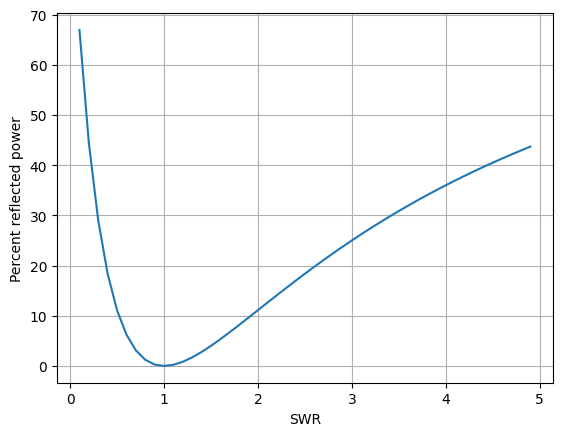

In [7]:
# Plot Reflected power
X = np.arange(0.1, 5.0, 0.1)
Y = Reflected(X)
plt.plot(X,Y*100)
plt.grid()
plt.xlabel('SWR')
plt.ylabel('Percent reflected power')

In [8]:
print('Ideal condition: ', Reflected(1.01))

Ideal condition:  2.475186257765902e-05


In [3]:
F = np.array([[28.0, 28.5, 29.0, 29.4], 
              [21, 21.2, 21.3, 21.4], 
              [14, 14.150, 14.2, 14.3]], dtype=np.float64)
# measured using a Bird throughline wattmeter with removable element
PF = np.array([[50, 50, 50, 10],
               [25, 50, 1, 1], 
               [50, 50, 1, 0.1]], dtype=np.float64)
PR = np.array([[18, 18, 7, 0.1], 
               [4,15, 0.9, 0.9],
               [2, 2.2, 0.9, 0.9]],
               dtype=np.float64)
value1 = SWR(PF[0],PR[0])
value2 = SWR(PF[1],PR[1])
value3 = SWR(PF[2],PR[2])
#
print(value1)

[4.         4.         2.19573428 1.22222222]


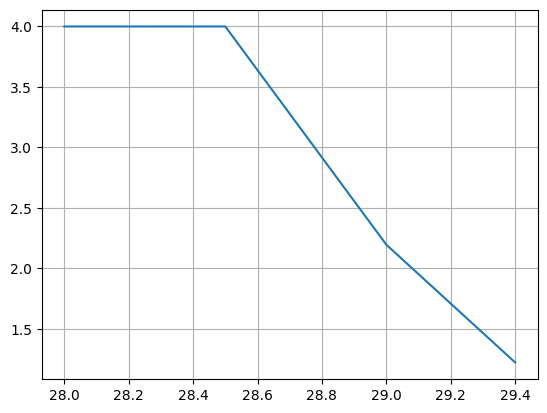

In [24]:
plt.plot(F[0],value1)
plt.grid()

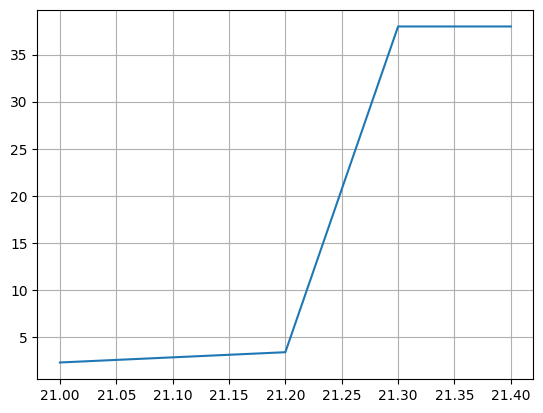

In [25]:
plt.plot(F[1],value2)
plt.grid()

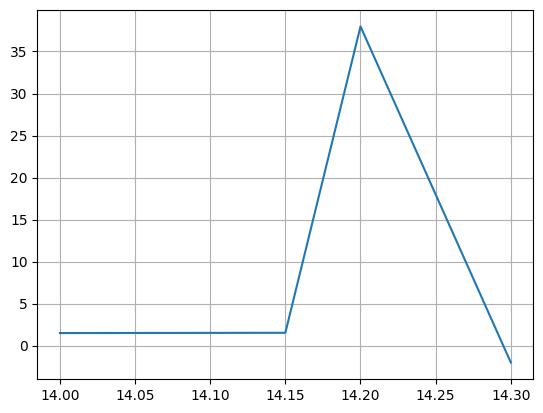

In [28]:
plt.plot(F[2],value3)
plt.grid()

Looks like 20m isn't too bad. 15m is a bit long, and 10m is a bit short. Should check to see if the orientation of the wires is causing an issue. It may be coupling to the HVAC!

In [8]:
s11db = -13.0
print("S11 value", s11db, " Calculated SWR: ", S11dB2SWR(s11db))

S11 value -13.0  Calculated SWR:  -1.1666666666666667
